In [1]:
# ==============================================================================
# PROJECT: Predicting Load-Shedding Events in Bangladesh's Power Grid
# AUTHOR: Zahidul Alam (Jeonbuk National University)
# YEAR: 2026
#
# LICENSE: All Rights Reserved.
# This code is proprietary. It may not be copied, distributed, published, or
# used to train machine learning models or generative AI systems without explicit
# written permission from the author.
# ==============================================================================

import sklearn
print(sklearn.__version__)


1.9.1


In [2]:
# ==============================================================================
# PROJECT: Predicting Load-Shedding Events in Bangladesh's Power Grid
# AUTHOR: Zahidul Alam (Jeonbuk National University)
# YEAR: 2026
#
# LICENSE: All Rights Reserved.
# This code is proprietary. It may not be copied, distributed, published, or
# used to train machine learning models or generative AI systems without explicit
# written permission from the author.
# ==============================================================================

import pandas as pd
import numpy as np

train = pd.read_csv("../data/processed/train_features.csv", parse_dates=["Date"])
test  = pd.read_csv("../data/processed/test_features.csv", parse_dates=["Date"])

divisions = ["Dhaka", "Chattogram", "Rajshahi", "Mymensingh", "Sylhet",
             "Barishal", "Rangpur", "Cumilla", "Khulna"]

# Explicit whitelist
feature_cols = ["day_of_week_num", "is_weekend", "month", "is_holiday",
                 "season_autumn", "season_monsoon", "season_summer", "season_winter",
                 "Minimum Generation Forecast up to 8:00 hrs.",
                 "kaptai_constrained_flag", "plants_down_wow_change"]
feature_cols += [c for c in train.columns if c.endswith(("_lag1", "_lag7", "_roll7_mean", "_roll7_std", "_roll14_mean", "_shed_count_7d"))]

print(f"Total predictors: {len(feature_cols)}")


Total predictors: 156


In [3]:
# ==============================================================================
# PROJECT: Predicting Load-Shedding Events in Bangladesh's Power Grid
# AUTHOR: Zahidul Alam (Jeonbuk National University)
# YEAR: 2026
#
# LICENSE: All Rights Reserved.
# This code is proprietary. It may not be copied, distributed, published, or
# used to train machine learning models or generative AI systems without explicit
# written permission from the author.
# ==============================================================================

target_div = "Dhaka"
y_train = train[f"{target_div}_shed"]
y_test  = test[f"{target_div}_shed"]
X_train = train[feature_cols]
X_test  = test[feature_cols]

print(y_train.mean(), y_test.mean())  # class balance is preserved across split


0.13458950201884254 0.42857142857142855


In [4]:
# ==============================================================================
# PROJECT: Predicting Load-Shedding Events in Bangladesh's Power Grid
# AUTHOR: Zahidul Alam (Jeonbuk National University)
# YEAR: 2026
#
# LICENSE: All Rights Reserved.
# This code is proprietary. It may not be copied, distributed, published, or
# used to train machine learning models or generative AI systems without explicit
# written permission from the author.
# ==============================================================================

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score, average_precision_score

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

logreg = LogisticRegression(max_iter=2000, class_weight="balanced")
logreg.fit(X_train_scaled, y_train)
proba = logreg.predict_proba(X_test_scaled)[:, 1]
preds = logreg.predict(X_test_scaled)

print(classification_report(y_test, preds))
print("ROC-AUC:", roc_auc_score(y_test, proba))
print("PR-AUC:", average_precision_score(y_test, proba))

              precision    recall  f1-score   support

         0.0       0.87      0.44      0.59       204
         1.0       0.55      0.92      0.69       153

    accuracy                           0.64       357
   macro avg       0.71      0.68      0.64       357
weighted avg       0.74      0.64      0.63       357

ROC-AUC: 0.8249070870178137
PR-AUC: 0.7806552891873485


In [5]:
# ==============================================================================
# PROJECT: Predicting Load-Shedding Events in Bangladesh's Power Grid
# AUTHOR: Zahidul Alam (Jeonbuk National University)
# YEAR: 2026
#
# LICENSE: All Rights Reserved.
# This code is proprietary. It may not be copied, distributed, published, or
# used to train machine learning models or generative AI systems without explicit
# written permission from the author.
# ==============================================================================

from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42)
rf.fit(X_train, y_train)
proba_rf = rf.predict_proba(X_test)[:, 1]
preds_rf = rf.predict(X_test)

print(classification_report(y_test, preds_rf))
print("ROC-AUC:", roc_auc_score(y_test, proba_rf))
print("PR-AUC:", average_precision_score(y_test, proba_rf))


              precision    recall  f1-score   support

         0.0       0.63      0.94      0.75       204
         1.0       0.76      0.27      0.40       153

    accuracy                           0.65       357
   macro avg       0.70      0.61      0.58       357
weighted avg       0.69      0.65      0.60       357

ROC-AUC: 0.7982666922978341
PR-AUC: 0.7176072708940309


In [6]:
# ==============================================================================
# PROJECT: Predicting Load-Shedding Events in Bangladesh's Power Grid
# AUTHOR: Zahidul Alam (Jeonbuk National University)
# YEAR: 2026
#
# LICENSE: All Rights Reserved.
# This code is proprietary. It may not be copied, distributed, published, or
# used to train machine learning models or generative AI systems without explicit
# written permission from the author.
# ==============================================================================

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             precision_score, recall_score, f1_score)

divisions = ["Dhaka", "Chattogram", "Rajshahi", "Mymensingh", "Sylhet",
             "Barishal", "Rangpur", "Cumilla", "Khulna"]

X_train = train[feature_cols]
X_test  = test[feature_cols]

# Scale once; fit on train only (used by LogReg)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)

def score(y_true, y_pred, y_prob):
    """Metrics computed directly (no classification_report parsing)."""
    return {
        "roc_auc":   roc_auc_score(y_true, y_prob),
        "pr_auc":    average_precision_score(y_true, y_prob),
        "recall":    recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "f1":        f1_score(y_true, y_pred, pos_label=1, zero_division=0),
    }

rows = []
for div in divisions:
    target = f"{div}_shed"
    y_train = train[target].astype(int).values
    y_test  = test[target].astype(int).values

    row = {
        "division": div,
        "train_shed_rate": y_train.mean(),
        "test_shed_rate":  y_test.mean(),
        "train_pos": int(y_train.sum()),
        "test_pos":  int(y_test.sum()),
    }

    # Logistic Regression (scaled)
    lr = LogisticRegression(max_iter=2000, class_weight="balanced")
    lr.fit(X_train_s, y_train)
    m = score(y_test, lr.predict(X_test_s), lr.predict_proba(X_test_s)[:, 1])
    row.update({f"logreg_{k}": v for k, v in m.items()})

    # Random Forest (unscaled)
    rf = RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                random_state=42, n_jobs=-1)
    rf.fit(X_train, y_train)
    m = score(y_test, rf.predict(X_test), rf.predict_proba(X_test)[:, 1])
    row.update({f"rf_{k}": v for k, v in m.items()})

    rows.append(row)
    print(f"done: {div}")

results = pd.DataFrame(rows).round(3)

import os
os.makedirs("../outputs/tables", exist_ok=True)   
results.to_csv("../outputs/tables/baseline_results_all_divisions.csv", index=False)

display(results)


done: Dhaka
done: Chattogram
done: Rajshahi
done: Mymensingh
done: Sylhet
done: Barishal
done: Rangpur
done: Cumilla
done: Khulna


,division,train_shed_rate,test_shed_rate,train_pos,test_pos,logreg_roc_auc,logreg_pr_auc,logreg_recall,logreg_precision,logreg_f1,rf_roc_auc,rf_pr_auc,rf_recall,rf_precision,rf_f1
0,Dhaka,0.135,0.429,200,153,0.825,0.781,0.915,0.551,0.688,0.798,0.718,0.275,0.764,0.404
1,Chattogram,0.038,0.092,56,33,0.374,0.070,0.152,0.037,0.059,0.729,0.247,0.000,0.000,0.000
2,Rajshahi,0.090,0.118,133,42,0.735,0.226,0.810,0.188,0.305,0.757,0.423,0.333,0.438,0.378
3,Mymensingh,0.217,0.555,322,198,0.818,0.842,0.919,0.679,0.781,0.849,0.843,0.894,0.750,0.816
4,Sylhet,0.109,0.162,162,58,0.755,0.420,0.776,0.238,0.364,0.842,0.463,0.414,0.545,0.471
5,Barishal,0.009,0.039,14,14,0.554,0.046,0.000,0.000,0.000,0.665,0.069,0.000,0.000,0.000
6,Rangpur,0.112,0.305,167,109,0.791,0.632,0.844,0.492,0.622,0.877,0.696,0.394,0.717,0.509
7,Cumilla,0.141,0.305,210,109,0.882,0.786,0.881,0.589,0.706,0.847,0.629,0.761,0.634,0.692
8,Khulna,0.076,0.132,113,47,0.681,0.270,0.596,0.203,0.303,0.756,0.378,0.234,0.688,0.349


In [7]:
# ==============================================================================
# PROJECT: Predicting Load-Shedding Events in Bangladesh's Power Grid
# AUTHOR: Zahidul Alam (Jeonbuk National University)
# YEAR: 2026
#
# LICENSE: All Rights Reserved.
# This code is proprietary. It may not be copied, distributed, published, or
# used to train machine learning models or generative AI systems without explicit
# written permission from the author.
# ==============================================================================

from sklearn.metrics import precision_recall_curve

VAL_DAYS = 180
MIN_VAL_POS = 5          # below this, the threshold is unreliable -> fall back to 0.5

def best_threshold(y_val, p_val):
    """Threshold that maximizes F1 on the validation slice."""
    if y_val.sum() < MIN_VAL_POS:
        return 0.5, False
    prec, rec, thr = precision_recall_curve(y_val, p_val)
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-9, None)
    return float(thr[np.argmax(f1)]), True

def make_lr():
    return LogisticRegression(max_iter=2000, class_weight="balanced")

def make_rf():
    return RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                  random_state=42, n_jobs=-1)

# Split train into sub-train / validation (chronological, no shuffle)
sub, val = train.iloc[:-VAL_DAYS], train.iloc[-VAL_DAYS:]
Xsub, Xval = sub[feature_cols], val[feature_cols]
Xtr,  Xte  = train[feature_cols], test[feature_cols]

# Scalers: one fit on sub-train (for tuning), one fit on full train (for final)
sc_sub  = StandardScaler().fit(Xsub)
sc_full = StandardScaler().fit(Xtr)

rows = []
for div in divisions:
    t = f"{div}_shed"
    y_sub = sub[t].astype(int).values
    y_val = val[t].astype(int).values
    y_tr  = train[t].astype(int).values
    y_te  = test[t].astype(int).values

    row = {"division": div, "val_pos": int(y_val.sum()),
           "train_shed_rate": y_tr.mean(), "test_shed_rate": y_te.mean(),
           "test_pos": int(y_te.sum())}

    for name, make, scaled in [("logreg", make_lr, True), ("rf", make_rf, False)]:
        # 1) tune threshold: fit on sub-train, predict validation
        m_tune = make()
        if scaled:
            m_tune.fit(sc_sub.transform(Xsub), y_sub)
            p_val = m_tune.predict_proba(sc_sub.transform(Xval))[:, 1]
        else:
            m_tune.fit(Xsub, y_sub)
            p_val = m_tune.predict_proba(Xval)[:, 1]
        thr, tuned = best_threshold(y_val, p_val)

        # 2) refit on full train, apply the chosen threshold to test once
        m_fin = make()
        if scaled:
            m_fin.fit(sc_full.transform(Xtr), y_tr)
            p_te = m_fin.predict_proba(sc_full.transform(Xte))[:, 1]
        else:
            m_fin.fit(Xtr, y_tr)
            p_te = m_fin.predict_proba(Xte)[:, 1]

        m = score(y_te, (p_te >= thr).astype(int), p_te)
        row[f"{name}_thr"] = round(thr, 3)
        row[f"{name}_tuned"] = tuned
        row.update({f"{name}_{k}": v for k, v in m.items()})

    rows.append(row)
    print(f"done: {div}")

results_tuned = pd.DataFrame(rows).round(3)
results_tuned.to_csv("../outputs/tables/baseline_results_tuned_threshold.csv", index=False)
display(results_tuned)


done: Dhaka
done: Chattogram
done: Rajshahi
done: Mymensingh
done: Sylhet
done: Barishal
done: Rangpur
done: Cumilla
done: Khulna


,division,val_pos,train_shed_rate,test_shed_rate,test_pos,logreg_thr,logreg_tuned,logreg_roc_auc,logreg_pr_auc,logreg_recall,logreg_precision,logreg_f1,rf_thr,rf_tuned,rf_roc_auc,rf_pr_auc,rf_recall,rf_precision,rf_f1
0,Dhaka,44,0.135,0.429,153,0.438,True,0.825,0.781,0.915,0.545,0.683,0.463,True,0.798,0.718,0.366,0.778,0.498
1,Chattogram,6,0.038,0.092,33,0.999,True,0.374,0.070,0.000,0.000,0.000,0.127,True,0.729,0.247,0.545,0.207,0.300
2,Rajshahi,26,0.090,0.118,42,0.796,True,0.735,0.226,0.786,0.217,0.340,0.357,True,0.757,0.423,0.500,0.226,0.311
3,Mymensingh,88,0.217,0.555,198,0.318,True,0.818,0.842,0.929,0.639,0.757,0.423,True,0.849,0.843,0.944,0.714,0.813
4,Sylhet,58,0.109,0.162,58,0.050,True,0.755,0.420,0.948,0.192,0.320,0.103,True,0.842,0.463,0.966,0.185,0.311
5,Barishal,1,0.009,0.039,14,0.500,False,0.554,0.046,0.000,0.000,0.000,0.500,False,0.665,0.069,0.000,0.000,0.000
6,Rangpur,49,0.112,0.305,109,0.964,True,0.791,0.632,0.642,0.556,0.596,0.423,True,0.877,0.696,0.624,0.673,0.648
7,Cumilla,68,0.141,0.305,109,0.978,True,0.882,0.786,0.642,0.722,0.680,0.250,True,0.847,0.629,0.963,0.488,0.648
8,Khulna,14,0.076,0.132,47,0.999,True,0.681,0.270,0.064,0.375,0.109,0.533,True,0.756,0.378,0.170,0.667,0.271


In [8]:
# ==============================================================================
# PROJECT: Predicting Load-Shedding Events in Bangladesh's Power Grid
# AUTHOR: Zahidul Alam (Jeonbuk National University)
# YEAR: 2026
#
# LICENSE: All Rights Reserved.
# This code is proprietary. It may not be copied, distributed, published, or
# used to train machine learning models or generative AI systems without explicit
# written permission from the author.
# ==============================================================================

import numpy as np
import pandas as pd
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             precision_recall_curve, precision_score,
                             recall_score, f1_score)

div = "Dhaka"
y_tr = train[f"{div}_load"].astype(float).values
y_te = test[f"{div}_load"].astype(float).values
b_tr = train[f"{div}_shed"].astype(int).values
b_te = test[f"{div}_shed"].astype(int).values

# sanity: confirm how the binary target relates to load
print("shed == (load > 0)?", bool(((y_tr > 0).astype(int) == b_tr).all()))
print("train load: min/mean/max =", y_tr.min(), round(y_tr.mean(), 2), y_tr.max())

# 1) Fit on train only
fit = ARIMA(y_tr, order=(1, 0, 1)).fit()
print(fit.summary().tables[1])

# 2) One-step-ahead forecasts across test, parameters frozen
ext = fit.append(y_te, refit=False)
pred_all = ext.fittedvalues            # prediction for day t uses data up to t-1
p_tr = pred_all[:len(y_tr)]
p_te = pred_all[len(y_tr):]
assert len(p_te) == len(y_te)

# 3) Threshold-free metrics on test
print("ROC-AUC:", round(roc_auc_score(b_te, p_te), 3))
print("PR-AUC :", round(average_precision_score(b_te, p_te), 3))

# 4) Threshold from last 180 train days, applied once to test
VAL = 180
prec, rec, thr = precision_recall_curve(b_tr[-VAL:], p_tr[-VAL:])
f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-9, None)
t_star = thr[np.argmax(f1)]
yhat = (p_te >= t_star).astype(int)
print("threshold:", round(float(t_star), 2))
print("recall   :", round(recall_score(b_te, yhat, zero_division=0), 3))
print("precision:", round(precision_score(b_te, yhat, zero_division=0), 3))
print("F1       :", round(f1_score(b_te, yhat, zero_division=0), 3))


shed == (load > 0)? True
train load: min/mean/max = 0.0 20.08 2002.0
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         20.0783     16.910      1.187      0.235     -13.065      53.222
ar.L1          0.9011      0.008    109.974      0.000       0.885       0.917
ma.L1         -0.5842      0.013    -43.796      0.000      -0.610      -0.558
sigma2      5330.4473     30.098    177.105      0.000    5271.457    5389.438
ROC-AUC: 0.849
PR-AUC : 0.792
threshold: 8.19
recall   : 0.915
precision: 0.636
F1       : 0.751


In [9]:
# ==============================================================================
# PROJECT: Predicting Load-Shedding Events in Bangladesh's Power Grid
# AUTHOR: Zahidul Alam (Jeonbuk National University)
# YEAR: 2026
#
# LICENSE: All Rights Reserved.
# This code is proprietary. It may not be copied, distributed, published, or
# used to train machine learning models or generative AI systems without explicit
# written permission from the author.
# ==============================================================================

from statsmodels.tsa.arima.model import ARIMA
import warnings
from statsmodels.tools.sm_exceptions import ConvergenceWarning

rows = []
for div in divisions:
    y_tr = train[f"{div}_load"].astype(float).values
    y_te = test[f"{div}_load"].astype(float).values
    b_tr = train[f"{div}_shed"].astype(int).values
    b_te = test[f"{div}_shed"].astype(int).values

    row = {"division": div, "train_shed_rate": b_tr.mean(),
           "test_shed_rate": b_te.mean(), "test_pos": int(b_te.sum())}
    try:
        with warnings.catch_warnings(record=True) as w:
            warnings.simplefilter("always")
            fit = ARIMA(y_tr, order=(1, 0, 1)).fit()
            row["converge_warn"] = any(issubclass(x.category, ConvergenceWarning) for x in w)

        pred = fit.append(y_te, refit=False).fittedvalues
        p_tr, p_te = pred[:len(y_tr)], pred[len(y_tr):]

        thr, tuned = best_threshold(b_tr[-180:], p_tr[-180:])
        m = score(b_te, (p_te >= thr).astype(int), p_te)

        # coefficients looked up by name: const, ar.L1, ma.L1, sigma2
        coef = dict(zip(fit.param_names, fit.params))
        row.update({"arima_thr": round(thr, 2), "arima_tuned": tuned,
                    "ar": round(coef["ar.L1"], 3),
                    "ma": round(coef["ma.L1"], 3),
                    "sigma2": round(coef["sigma2"], 1)})
        row.update({f"arima_{k}": v for k, v in m.items()})
    except Exception as e:
        row["error"] = str(e)[:80]
    rows.append(row)
    print("done:", div)

results_arima = pd.DataFrame(rows).round(3)
results_arima.to_csv("../outputs/tables/baseline_results_arima.csv", index=False)
display(results_arima)

done: Dhaka
done: Chattogram
done: Rajshahi
done: Mymensingh
done: Sylhet
done: Barishal
done: Rangpur
done: Cumilla
done: Khulna


,division,train_shed_rate,test_shed_rate,test_pos,converge_warn,arima_thr,arima_tuned,ar,ma,sigma2,arima_roc_auc,arima_pr_auc,arima_recall,arima_precision,arima_f1
0,Dhaka,0.135,0.429,153,False,8.19,True,0.901,-0.584,5330.4,0.849,0.792,0.915,0.636,0.751
1,Chattogram,0.038,0.092,33,False,11.81,True,0.849,-0.653,717.2,0.833,0.471,0.636,0.368,0.467
2,Rajshahi,0.090,0.118,42,False,12.49,True,0.843,-0.380,838.1,0.785,0.543,0.667,0.431,0.523
3,Mymensingh,0.217,0.555,198,False,19.97,True,0.951,-0.565,1567.7,0.837,0.850,0.924,0.744,0.824
4,Sylhet,0.109,0.162,58,False,5.61,True,0.934,-0.680,375.6,0.808,0.544,0.724,0.393,0.509
5,Barishal,0.009,0.039,14,False,0.50,False,0.844,-0.419,19.8,0.716,0.232,0.500,0.152,0.233
6,Rangpur,0.112,0.305,109,False,14.76,True,0.805,-0.266,638.0,0.897,0.789,0.752,0.683,0.716
7,Cumilla,0.141,0.305,109,False,15.13,True,0.878,-0.372,1050.6,0.816,0.666,0.642,0.593,0.617
8,Khulna,0.076,0.132,47,False,65.21,True,0.840,-0.359,1135.8,0.719,0.375,0.255,0.545,0.348


In [10]:
# ==============================================================================
# PROJECT: Predicting Load-Shedding Events in Bangladesh's Power Grid
# AUTHOR: Zahidul Alam (Jeonbuk National University)
# YEAR: 2026
#
# LICENSE: All Rights Reserved.
# This code is proprietary. It may not be copied, distributed, published, or
# used to train machine learning models or generative AI systems without explicit
# written permission from the author.
# ==============================================================================

import pandas as pd
a = pd.read_csv("../outputs/tables/baseline_results_all_divisions.csv")
b = pd.read_csv("../outputs/tables/baseline_results_tuned_threshold.csv")
c = pd.read_csv("../outputs/tables/baseline_results_arima.csv")

combined = pd.DataFrame({
    "division":        a["division"],
    "test_shed_rate":  a["test_shed_rate"],
    "ARIMA_roc":       c["arima_roc_auc"], "RF_roc": a["rf_roc_auc"], "LogReg_roc": a["logreg_roc_auc"],
    "ARIMA_pr":        c["arima_pr_auc"],  "RF_pr":  a["rf_pr_auc"],  "LogReg_pr":  a["logreg_pr_auc"],
    "ARIMA_f1":        c["arima_f1"],      "RF_f1_tuned": b["rf_f1"], "LogReg_f1_tuned": b["logreg_f1"],
})
combined.loc[len(combined)] = ["MACRO AVG"] + combined.drop(columns="division").mean().round(3).tolist()
combined.round(3).to_csv("../outputs/tables/phase3_combined_baselines.csv", index=False)
display(combined.round(3))


,division,test_shed_rate,ARIMA_roc,RF_roc,LogReg_roc,ARIMA_pr,RF_pr,LogReg_pr,ARIMA_f1,RF_f1_tuned,LogReg_f1_tuned
0,Dhaka,0.429,0.849,0.798,0.825,0.792,0.718,0.781,0.751,0.498,0.683
1,Chattogram,0.092,0.833,0.729,0.374,0.471,0.247,0.070,0.467,0.300,0.000
2,Rajshahi,0.118,0.785,0.757,0.735,0.543,0.423,0.226,0.523,0.311,0.340
3,Mymensingh,0.555,0.837,0.849,0.818,0.850,0.843,0.842,0.824,0.813,0.757
4,Sylhet,0.162,0.808,0.842,0.755,0.544,0.463,0.420,0.509,0.311,0.320
5,Barishal,0.039,0.716,0.665,0.554,0.232,0.069,0.046,0.233,0.000,0.000
6,Rangpur,0.305,0.897,0.877,0.791,0.789,0.696,0.632,0.716,0.648,0.596
7,Cumilla,0.305,0.816,0.847,0.882,0.666,0.629,0.786,0.617,0.648,0.680
8,Khulna,0.132,0.719,0.756,0.681,0.375,0.378,0.270,0.348,0.271,0.109
9,MACRO AVG,0.237,0.807,0.791,0.713,0.585,0.496,0.453,0.554,0.422,0.387


In [11]:
# ==============================================================================
# PROJECT: Predicting Load-Shedding Events in Bangladesh's Power Grid
# AUTHOR: Zahidul Alam (Jeonbuk National University)
# YEAR: 2026
#
# LICENSE: All Rights Reserved.
# This code is proprietary. It may not be copied, distributed, published, or
# used to train machine learning models or generative AI systems without explicit
# written permission from the author.
# ==============================================================================

# -ARIMA-save: save ARIMA test scores and verify against the saved metrics table
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import roc_auc_score, average_precision_score
import warnings, numpy as np, pandas as pd

ref = pd.read_csv("../outputs/tables/baseline_results_arima.csv")
p_arima = np.zeros((len(divisions), len(test)))
chk = []
for i, d in enumerate(divisions):
    y_tr_l = train[f"{d}_load"].astype(float).values
    y_te_l = test[f"{d}_load"].astype(float).values
    b_te   = test[f"{d}_shed"].astype(int).values
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        fit = ARIMA(y_tr_l, order=(1, 0, 1)).fit()
        pred = fit.append(y_te_l, refit=False).fittedvalues
    p_arima[i] = pred[len(y_tr_l):]
    chk.append(dict(division=d,
                    roc=round(roc_auc_score(b_te, p_arima[i]), 3),
                    roc_saved=ref.loc[ref.division == d, "arima_roc_auc"].values[0],
                    pr=round(average_precision_score(b_te, p_arima[i]), 3),
                    pr_saved=ref.loc[ref.division == d, "arima_pr_auc"].values[0]))
chk = pd.DataFrame(chk)
print(chk.to_string(index=False))
print("max abs diff  ROC:", (chk.roc - chk.roc_saved).abs().max().round(4),
      " PR:", (chk.pr - chk.pr_saved).abs().max().round(4))

np.save("../data/processed/p_arima.npy", p_arima)

  division   roc  roc_saved    pr  pr_saved
     Dhaka 0.849      0.849 0.792     0.792
Chattogram 0.833      0.833 0.471     0.471
  Rajshahi 0.785      0.785 0.543     0.543
Mymensingh 0.837      0.837 0.850     0.850
    Sylhet 0.808      0.808 0.544     0.544
  Barishal 0.716      0.716 0.232     0.232
   Rangpur 0.897      0.897 0.789     0.789
   Cumilla 0.816      0.816 0.666     0.666
    Khulna 0.719      0.719 0.375     0.375
max abs diff  ROC: 0.0  PR: 0.0


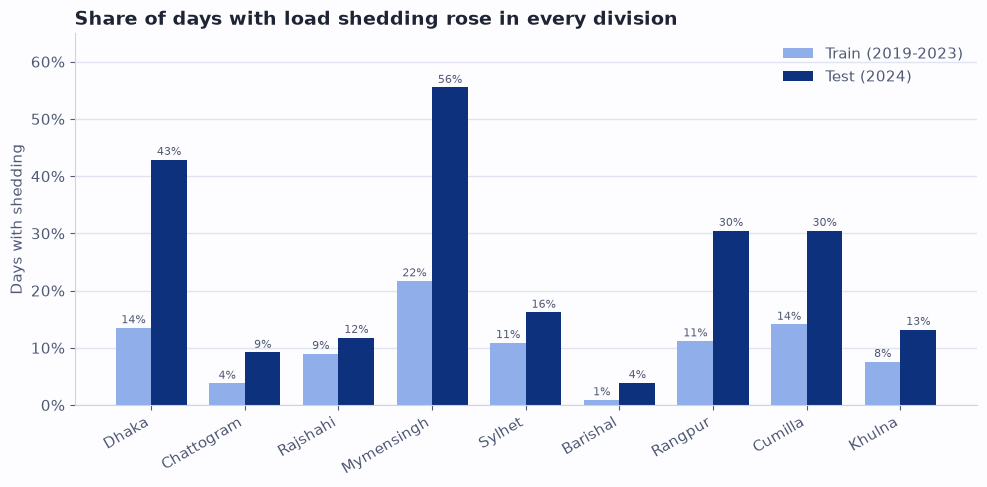

saved fig1_shedding_shift.png


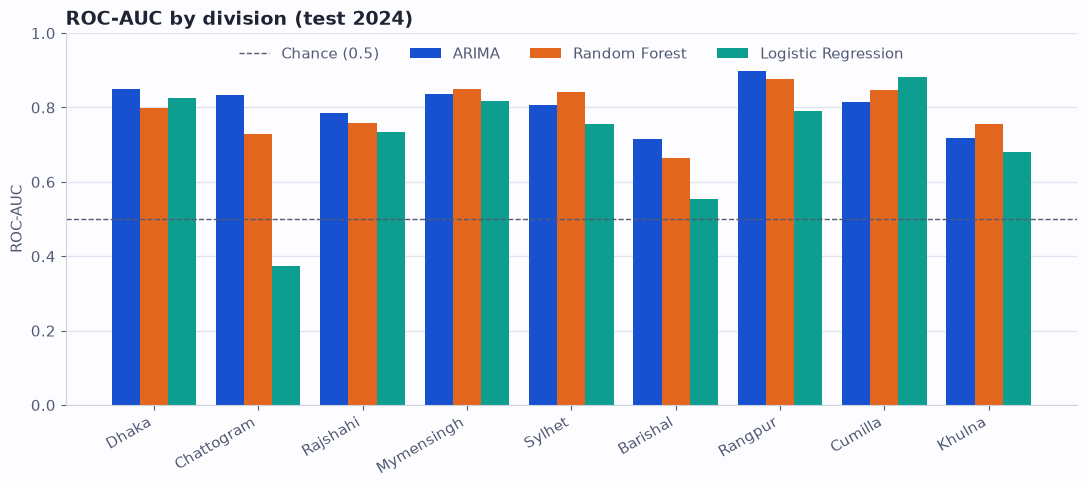

saved fig2_roc_auc.png


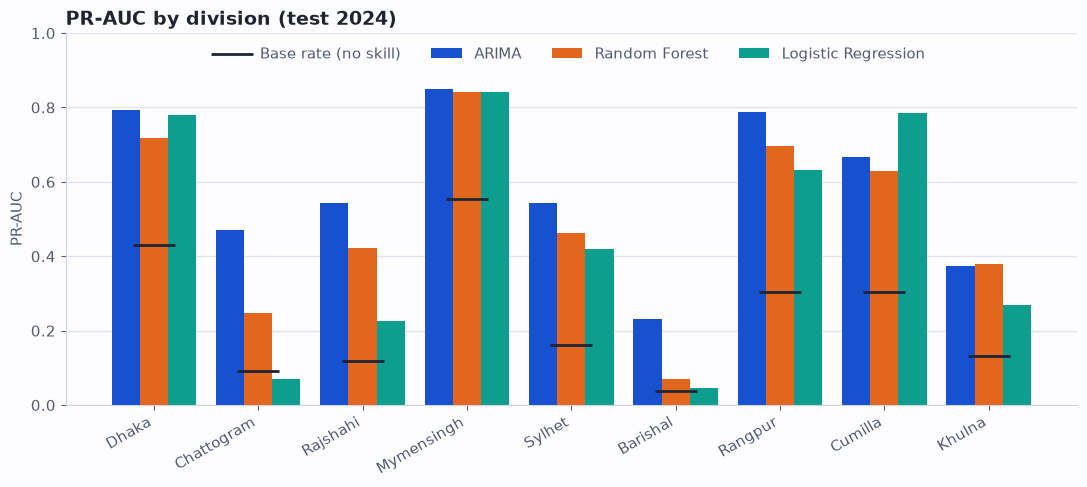

saved fig3_pr_auc.png


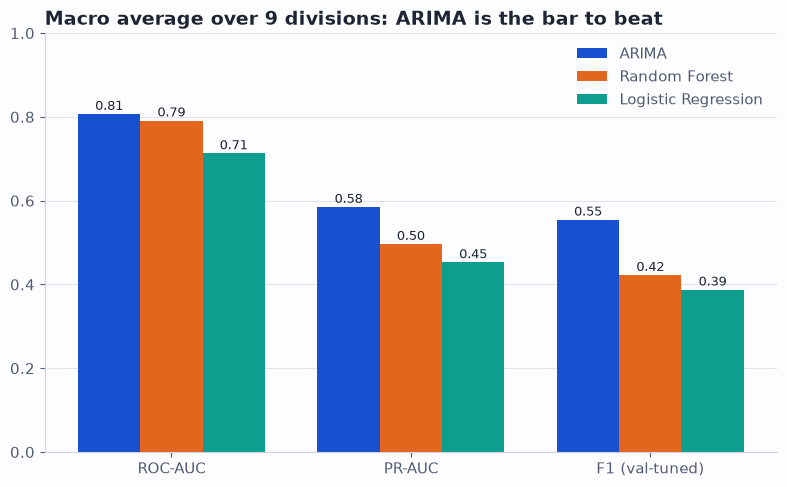

saved fig4_macro_summary.png


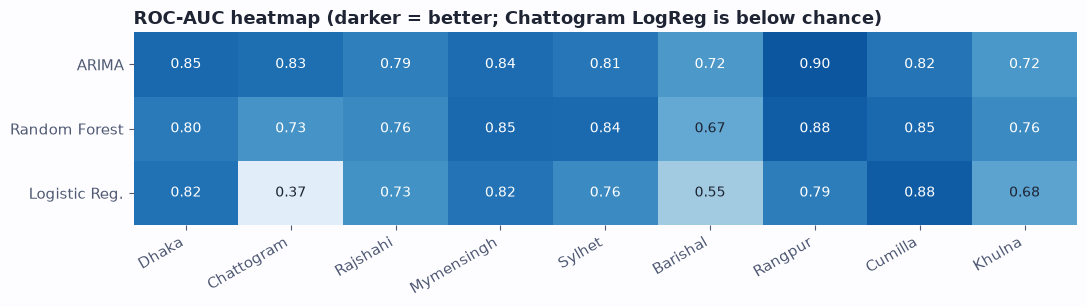

saved fig5_roc_heatmap.png


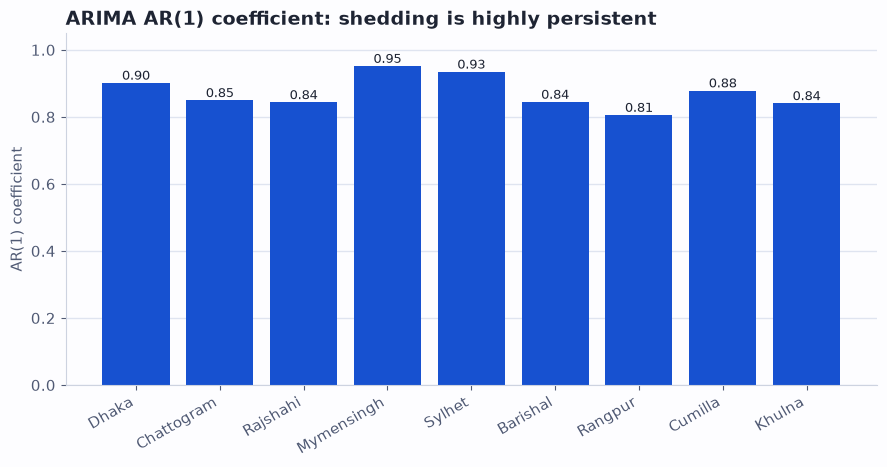

saved fig6_arima_persistence.png


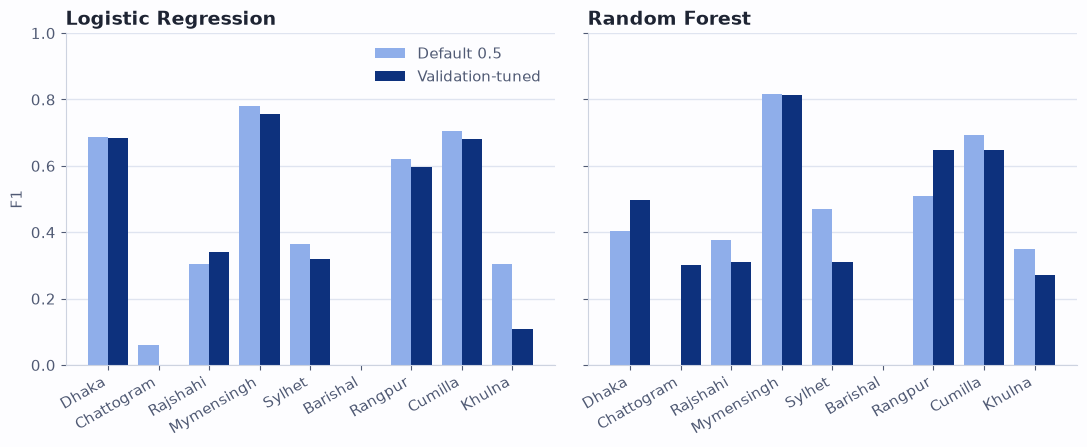

saved fig7_threshold_tuning.png


In [12]:
# ==============================================================================
# PROJECT: Predicting Load-Shedding Events in Bangladesh's Power Grid
# AUTHOR: Zahidul Alam (Jeonbuk National University)
# YEAR: 2026
#
# LICENSE: All Rights Reserved.
# This code is proprietary. It may not be copied, distributed, published, or
# used to train machine learning models or generative AI systems without explicit
# written permission from the author.
# ==============================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TABLES  = "../outputs/tables"    
FIGURES = "../outputs/figures"
os.makedirs(FIGURES, exist_ok=True)

# house palette (blue, orange, aqua) + ink/grid
BLUE, ORANGE, AQUA = "#1751D0", "#E2661E", "#0E9E8F"
LIGHT_BLUE, NAVY = "#8FAEEA", "#0D317D"
INK, INK2, GRID, SURF = "#1E2433", "#505A74", "#DFE4F0", "#FDFDFF"
plt.rcParams.update({"font.size": 11, "axes.edgecolor": "#CDD3E0", "axes.labelcolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK2, "figure.facecolor": SURF,
                     "axes.facecolor": SURF, "axes.spines.top": False, "axes.spines.right": False})

a = pd.read_csv(f"{TABLES}/baseline_results_all_divisions.csv")
b = pd.read_csv(f"{TABLES}/baseline_results_tuned_threshold.csv")
c = pd.read_csv(f"{TABLES}/baseline_results_arima.csv")
div = a["division"].tolist()
x = np.arange(len(div))

def style(ax, title, ylabel=None, ymax=None, pct=False):
    ax.set_title(title, loc="left", color=INK, fontsize=14, fontweight="bold")
    if ylabel: ax.set_ylabel(ylabel)
    ax.grid(axis="y", color=GRID, linewidth=1); ax.set_axisbelow(True)
    ax.set_xticks(x); ax.set_xticklabels(div, rotation=30, ha="right")
    if ymax: ax.set_ylim(0, ymax)
    if pct: ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")

def save(fig, name):
    fig.tight_layout(); fig.savefig(f"{FIGURES}/{name}", dpi=200, facecolor=SURF)
    plt.show(); print("saved", name)

# Fig 1: train vs test shedding rate (the 2024 shift)
fig, ax = plt.subplots(figsize=(10, 5)); w = 0.38
ax.bar(x - w/2, a["train_shed_rate"], w, color=LIGHT_BLUE, label="Train (2019-2023)")
ax.bar(x + w/2, a["test_shed_rate"],  w, color=NAVY,       label="Test (2024)")
for i, (t, s) in enumerate(zip(a["train_shed_rate"], a["test_shed_rate"])):
    ax.text(i - w/2, t + .008, f"{t:.0%}", ha="center", fontsize=8, color=INK2)
    ax.text(i + w/2, s + .008, f"{s:.0%}", ha="center", fontsize=8, color=INK2)
style(ax, "Share of days with load shedding rose in every division", "Days with shedding", 0.65, pct=True)
ax.legend(frameon=False, labelcolor=INK2); save(fig, "fig1_shedding_shift.png")

# Fig 2 and 3: ROC-AUC and PR-AUC by division
def three_bar(arima, rf, lr, title, ylabel, fname, base=None):
    fig, ax = plt.subplots(figsize=(11, 5)); w = 0.27
    ax.bar(x - w, arima, w, color=BLUE,   label="ARIMA")
    ax.bar(x,     rf,    w, color=ORANGE, label="Random Forest")
    ax.bar(x + w, lr,    w, color=AQUA,   label="Logistic Regression")
    style(ax, title, ylabel, 1.0)
    if base is not None:
        ax.scatter(x, base, marker="_", s=900, color=INK, linewidths=2, zorder=5, label="Base rate (no skill)")
    else:
        ax.axhline(0.5, color=INK2, linestyle="--", linewidth=1, label="Chance (0.5)")
    ax.legend(frameon=False, labelcolor=INK2, ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.0))
    save(fig, fname)

three_bar(c["arima_roc_auc"], a["rf_roc_auc"], a["logreg_roc_auc"],
          "ROC-AUC by division (test 2024)", "ROC-AUC", "fig2_roc_auc.png")
three_bar(c["arima_pr_auc"], a["rf_pr_auc"], a["logreg_pr_auc"],
          "PR-AUC by division (test 2024)", "PR-AUC", "fig3_pr_auc.png", base=a["test_shed_rate"])

# Fig 4: macro averages
metrics = ["ROC-AUC", "PR-AUC", "F1 (val-tuned)"]
vals = {"ARIMA": [c["arima_roc_auc"].mean(), c["arima_pr_auc"].mean(), c["arima_f1"].mean()],
        "Random Forest": [a["rf_roc_auc"].mean(), a["rf_pr_auc"].mean(), b["rf_f1"].mean()],
        "Logistic Regression": [a["logreg_roc_auc"].mean(), a["logreg_pr_auc"].mean(), b["logreg_f1"].mean()]}
fig, ax = plt.subplots(figsize=(8, 5)); w = 0.26; xm = np.arange(3)
for k, (name, col) in enumerate(zip(vals, [BLUE, ORANGE, AQUA])):
    bars = ax.bar(xm + (k - 1) * w, vals[name], w, color=col, label=name)
    for r in bars: ax.text(r.get_x() + r.get_width()/2, r.get_height() + .01, f"{r.get_height():.2f}", ha="center", fontsize=9, color=INK)
ax.set_xticks(xm); ax.set_xticklabels(metrics); ax.set_ylim(0, 1)
ax.set_title("Macro average over 9 divisions: ARIMA is the bar to beat", loc="left", color=INK, fontsize=14, fontweight="bold")
ax.grid(axis="y", color=GRID); ax.set_axisbelow(True); ax.legend(frameon=False, labelcolor=INK2)
save(fig, "fig4_macro_summary.png")

# Fig 5: heatmap of ROC-AUC (model x division)
M = np.array([c["arima_roc_auc"], a["rf_roc_auc"], a["logreg_roc_auc"]])
fig, ax = plt.subplots(figsize=(11, 3.2))
im = ax.imshow(M, cmap=plt.cm.Blues, vmin=0.3, vmax=1.0, aspect="auto")
ax.set_xticks(x); ax.set_xticklabels(div, rotation=30, ha="right")
ax.set_yticks(range(3)); ax.set_yticklabels(["ARIMA", "Random Forest", "Logistic Reg."])
for i in range(3):
    for j in range(len(div)):
        ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=10,
                color="white" if M[i, j] > 0.7 else INK)
ax.spines[:].set_visible(False)
ax.set_title("ROC-AUC heatmap (darker = better; Chattogram LogReg is below chance)", loc="left", color=INK, fontsize=13, fontweight="bold")
save(fig, "fig5_roc_heatmap.png")

# Fig 6: AR(1) persistence
fig, ax = plt.subplots(figsize=(9, 4.8))
bars = ax.bar(x, c["ar"], color=BLUE)
for r in bars: ax.text(r.get_x() + r.get_width()/2, r.get_height() + .01, f"{r.get_height():.2f}", ha="center", fontsize=9, color=INK)
style(ax, "ARIMA AR(1) coefficient: shedding is highly persistent", "AR(1) coefficient", 1.05)
save(fig, "fig6_arima_persistence.png")

# Fig 7: default vs tuned threshold, F1 per division is in the CSVs; macro below uses tuned file for tuned and
# the all-divisions file for the default-cutoff F1 if the column exists
if "logreg_f1" in a.columns and "rf_f1" in a.columns:
    fig, axs = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
    for ax, key, name in zip(axs, ["logreg", "rf"], ["Logistic Regression", "Random Forest"]):
        ax.bar(x - .2, a[f"{key}_f1"], .4, color=LIGHT_BLUE, label="Default 0.5")
        ax.bar(x + .2, b[f"{key}_f1"], .4, color=NAVY, label="Validation-tuned")
        style(ax, name, "F1" if key == "logreg" else None, 1.0)
    axs[0].legend(frameon=False, labelcolor=INK2); save(fig, "fig7_threshold_tuning.png")
else:
    print("fig7 skipped: baseline_results_all_divisions.csv has no logreg_f1/rf_f1 columns")
